In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/fedesoriano/heart-failure-prediction/heart.csv


# Import e carga dos dados
Lê o arquivo heart.csv baixado do Kaggle e carrega em um DataFrame do pandas, que é a estrutura usada para manipular os dados em formato de tabela.

In [2]:
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

df=pd.read_csv(r"/kaggle/input/datasets/fedesoriano/heart-failure-prediction/heart.csv")
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


# Avaliação do banco de dados
Faz uma análise exploratória antes de tratar qualquer coisa: quantos pacientes têm/não têm a doença, como as variáveis numéricas se distribuem, correlação entre elas, e checagem de valores suspeitos (0) em RestingBP e Cholesterol.

In [3]:
print("Dimencoes:", df.shape)
df.info()
df.describe()

Dimencoes: (918, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB


,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,0.233115,136.809368,0.887364,0.553377
std,9.432617,18.514154,109.384145,0.423046,25.460334,1.066570,0.497414
min,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


# Graficos para compreensão do datasset

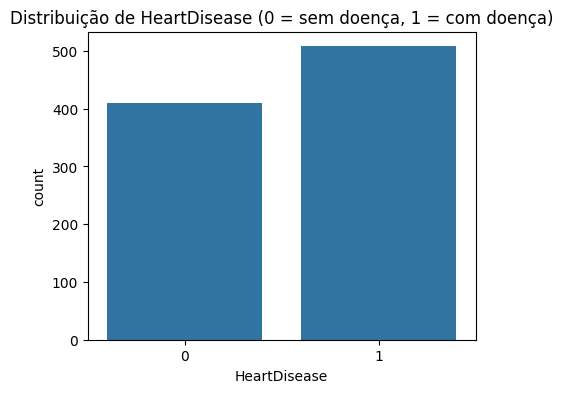

In [4]:
# Quantos pacientes tem ou não a doença
plt.figure(figsize=(5,4))
sns.countplot(x='HeartDisease', data=df)
plt.title('Distribuição de HeartDisease (0 = sem doença, 1 = com doença)')
plt.show()

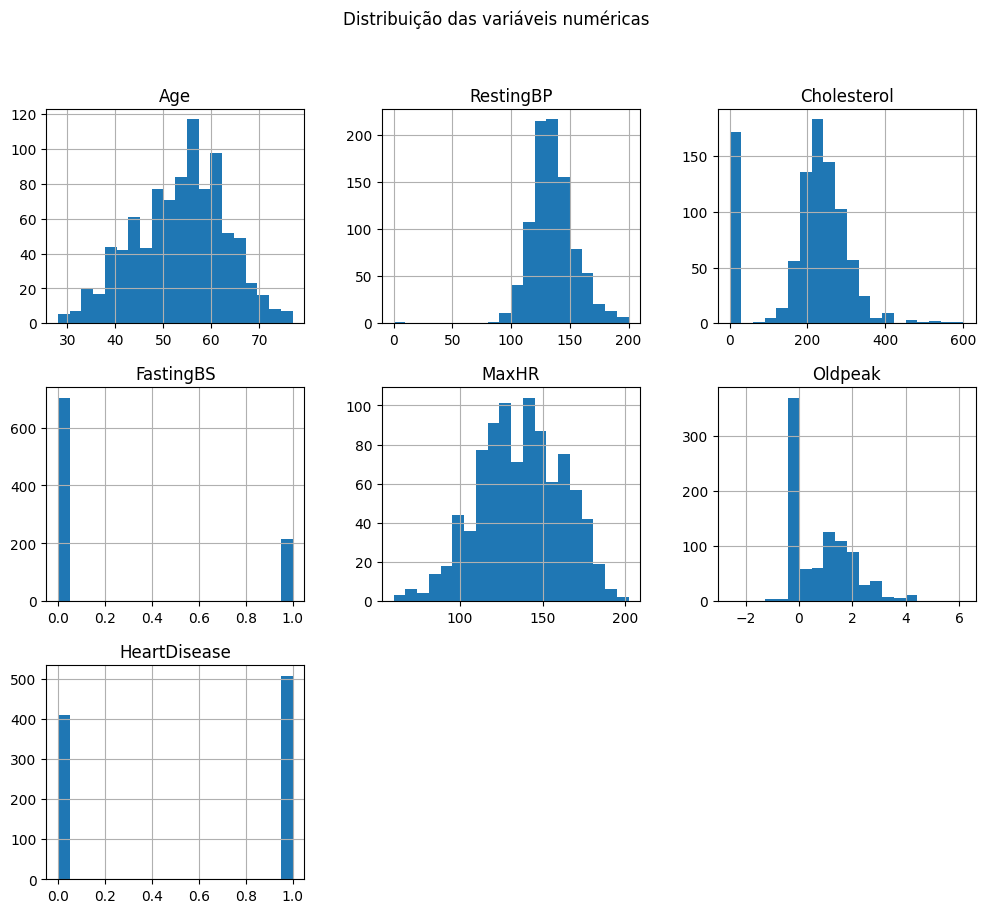

In [5]:
# Como cada variavel numerica se comporta

df.hist(figsize=(12,10), bins=20)
plt.suptitle('Distribuição das variáveis numéricas')
plt.show()

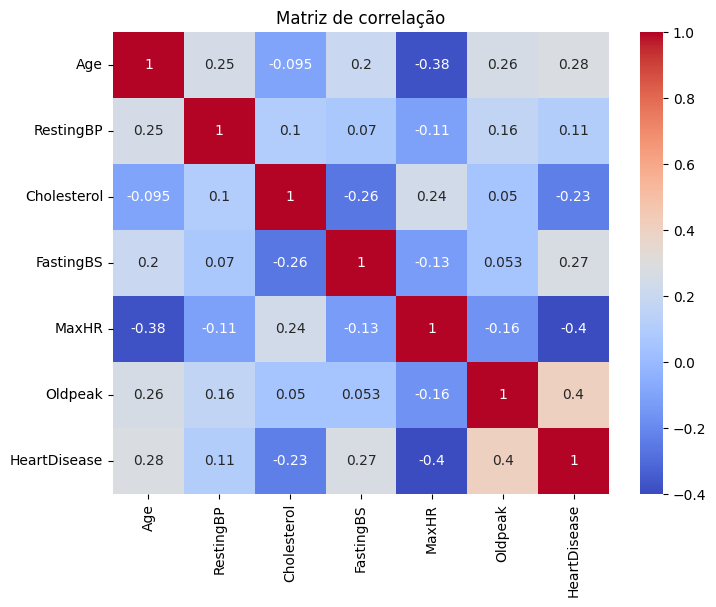

In [6]:
# Quais variaveis parecem estar relacionadas

plt.figure(figsize=(8,6))
sns.heatmap(df.select_dtypes(include='number').corr(), annot=True, cmap='coolwarm')
plt.title('Matriz de correlação')
plt.show()


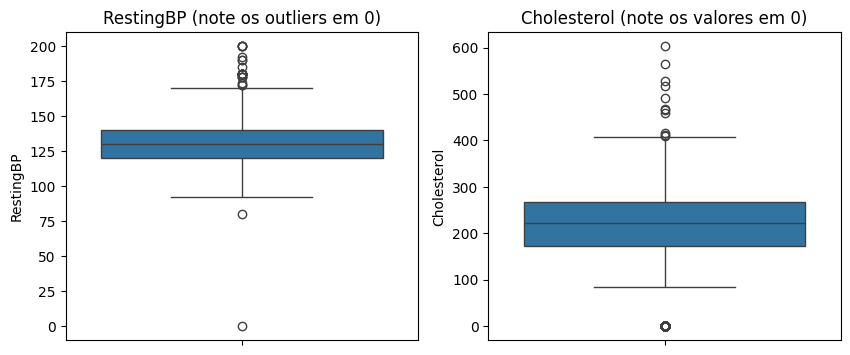

In [7]:
# RestingBP e Cholesterol não podem ser 0 na vida real

fig, axes = plt.subplots(1, 2, figsize=(10,4))
sns.boxplot(y=df['RestingBP'], ax=axes[0])
axes[0].set_title('RestingBP (note os outliers em 0)')
sns.boxplot(y=df['Cholesterol'], ax=axes[1])
axes[1].set_title('Cholesterol (note os valores em 0)')
plt.show()

# Tratativa de dados ausentes
RestingBP e Cholesterol não podem ser 0 na vida real, esses zeros são dados ausentes disfarçados. Substituímos cada um pela mediana dos valores válidos da própria coluna.

In [8]:
print("Valores nulos por coluna:\n", df.isnull().sum())
print("\nRestingBP = 0:", (df['RestingBP'] == 0).sum())
print("Cholesterol = 0:", (df['Cholesterol'] == 0).sum())
mediana_bp = df.loc[df['RestingBP'] != 0, 'RestingBP'].median()
df['RestingBP'] = df['RestingBP'].replace(0, mediana_bp)
mediana_chol = df.loc[df['Cholesterol'] != 0, 'Cholesterol'].median()
df['Cholesterol'] = df['Cholesterol'].replace(0, mediana_chol)
print("\nApós tratamento:")
print("RestingBP = 0:", (df['RestingBP'] == 0).sum())
print("Cholesterol = 0:", (df['Cholesterol'] == 0).sum())

Valores nulos por coluna:
 Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64

RestingBP = 0: 1
Cholesterol = 0: 172

Após tratamento:
RestingBP = 0: 0
Cholesterol = 0: 0


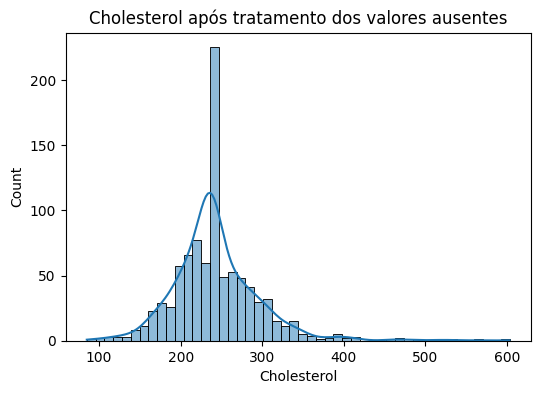

In [9]:
# Comparação do grafico antes e depois
plt.figure(figsize=(6,4))
sns.histplot(df['Cholesterol'], kde=True)
plt.title('Cholesterol após tratamento dos valores ausentes')
plt.show()

# Tratativa de encoding
O modelo só entende número. Sexo e ExerciseAngina viram 0/1 (binárias). ST_Slope tem ordem clínica, vira 0/1/2 (ordinal). ChestPainType e RestingECG não têm ordem, viram One-Hot Encoding (uma coluna binária pra cada categoria).

In [10]:
df['Sex'] = df['Sex'].map({'M': 1, 'F': 0})
df['ExerciseAngina'] = df['ExerciseAngina'].map({'Y': 1, 'N': 0})

df['ST_Slope'] = df['ST_Slope'].map({'Down': 0, 'Flat': 1, 'Up': 2})

df = pd.get_dummies(df, columns=['ChestPainType', 'RestingECG'], drop_first=True)
df.head()

,Age,Sex,RestingBP,Cholesterol,FastingBS,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_Normal,RestingECG_ST
0,40,1,140,289,0,172,0,0.0,2,0,True,False,False,True,False
1,49,0,160,180,0,156,0,1.0,1,1,False,True,False,True,False
2,37,1,130,283,0,98,0,0.0,2,0,True,False,False,False,True
3,48,0,138,214,0,108,1,1.5,1,1,False,False,False,True,False
4,54,1,150,195,0,122,0,0.0,2,0,False,True,False,True,False


In [11]:
# Checagem final
print("Formato final:", df.shape)
df.info()

Formato final: (918, 15)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Age                918 non-null    int64  
 1   Sex                918 non-null    int64  
 2   RestingBP          918 non-null    int64  
 3   Cholesterol        918 non-null    int64  
 4   FastingBS          918 non-null    int64  
 5   MaxHR              918 non-null    int64  
 6   ExerciseAngina     918 non-null    int64  
 7   Oldpeak            918 non-null    float64
 8   ST_Slope           918 non-null    int64  
 9   HeartDisease       918 non-null    int64  
 10  ChestPainType_ATA  918 non-null    bool   
 11  ChestPainType_NAP  918 non-null    bool   
 12  ChestPainType_TA   918 non-null    bool   
 13  RestingECG_Normal  918 non-null    bool   
 14  RestingECG_ST      918 non-null    bool   
dtypes: bool(5), float64(1), int64(9)
memory usage: 76

In [12]:
# Importando as bibliotecas necessarias
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.decomposition import PCA
import numpy as np
from sklearn.metrics import roc_curve, roc_auc_score

# Preparando os dados para o treinamento
 
Precisamos separar duas coisas: as
características do paciente que o modelo vai usar para decidir
(`X`) e a resposta que ele deve aprender a prever, se tem ou não doença
cardíaca (`y`). Também precisamos colocar as variáveis numéricas na
mesma escala, porque o SVM mede distâncias entre os pontos, se uma
variável tiver valores muito maiores que outra (ex: Colesterol vs. Sexo),
ela dominaria o cálculo sem motivo real.

In [13]:
X = df.drop(columns='HeartDisease')
y = df['HeartDisease']
 
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Separar treino e teste
 
Separamos uma parte dos dados (teste) que o modelo
nunca vê durante o aprendizado, para avaliar de forma honesta e depois
usamos `stratify=y` para manter a mesma proporção de pacientes com e
sem doença nos dois grupos.

In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42, stratify=y
)
 
print("Treino:", X_train.shape[0], "pacientes")
print("Teste:", X_test.shape[0], "pacientes")

Treino: 734 pacientes
Teste: 184 pacientes


# Escolhendo os parâmetros do SVM
 
O SVM tem parâmetros que mudam bastante seu comportamento, como o
`kernel` (a forma como ele separa as classes), o `C` (o quanto ele
tolera erros durante o aprendizado) e o `gamma` (o quanto cada ponto
influencia os vizinhos). Em vez de testar valores à mão, usamos o
GridSearchCV, que testa várias combinações automaticamente e, usando
validação cruzada, escolhe a combinação que generaliza melhor, ou
seja, que funciona bem além dos dados de treino.

In [15]:
param_grid = {
    'kernel': ['linear', 'rbf'],
    'C': [0.1, 1, 10, 100],
    'gamma': ['scale', 0.01, 0.1, 1]
}
 
grid = GridSearchCV(SVC(), param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid.fit(X_train, y_train)
 
print("Melhores parâmetros encontrados:", grid.best_params_)
print("Melhor acurácia média na validação:", grid.best_score_)

Melhores parâmetros encontrados: {'C': 1, 'gamma': 'scale', 'kernel': 'linear'}
Melhor acurácia média na validação: 0.8541794800111825


# Treinando os melhores parâmetros e avaliando no teste
 
Agora pegamos a combinação de parâmetros que o GridSearchCV apontou como
a melhor e treinamos o modelo definitivo. Em seguida, aplicamos esse
modelo nos dados de teste, que ele nunca viu, para ter uma ideia
realista de como ele se sairia com pacientes novos.

In [16]:
melhor_modelo = grid.best_estimator_
y_pred = melhor_modelo.predict(X_test)
 
print("Acurácia no teste:", accuracy_score(y_test, y_pred))
print("\nRelatório de classificação:\n", classification_report(y_test, y_pred))

Acurácia no teste: 0.8695652173913043

Relatório de classificação:
               precision    recall  f1-score   support

           0       0.88      0.82      0.85        82
           1       0.86      0.91      0.89       102

    accuracy                           0.87       184
   macro avg       0.87      0.86      0.87       184
weighted avg       0.87      0.87      0.87       184



# Acertos e Erros
 
A matriz de confusão mostra, de forma visual, quantos pacientes o
modelo classificou corretamente e onde ele errou, separando os casos
em que ele previu "sem doença" quando na verdade havia doença (e
vice-versa). Isso é especialmente importante em contexto de saúde,
onde um falso negativo (dizer que o paciente está saudável quando não
está) é mais grave que um falso positivo.

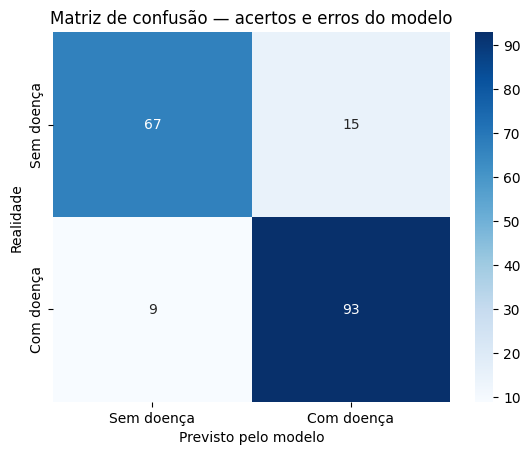

In [17]:
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Sem doença', 'Com doença'],
            yticklabels=['Sem doença', 'Com doença'])
plt.xlabel('Previsto pelo modelo')
plt.ylabel('Realidade')
plt.title('Matriz de confusão — acertos e erros do modelo')
plt.show()